In [17]:
# ==========================================
# Cell 1: Import Libraries and Run Pipeline
# ==========================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

from src.pipeline import (
    run_baselines,
    trivial_segmentation,
    simple_segmentation,
    trivial_restoration,
    simple_restoration
)

from src.data import (
    load_image,
    load_ground_truth,
    degrade_image
)

# Run baseline evaluation
train_pairs, test_pairs, results = run_baselines()

Training Samples: 700
Testing Samples: 300
DATASET SPLIT
Training Samples: 700
Testing Samples: 300

BASELINE RESULTS

Segmentation Results
Trivial Baseline IoU: 0.2382
Simple Baseline IoU: 0.2408

Restoration Results
Trivial Baseline MSE: 539.02
Trivial Baseline PSNR: 20.82 dB
Simple Baseline MSE: 109.23
Simple Baseline PSNR: 27.76 dB

Baseline Evaluation Completed!


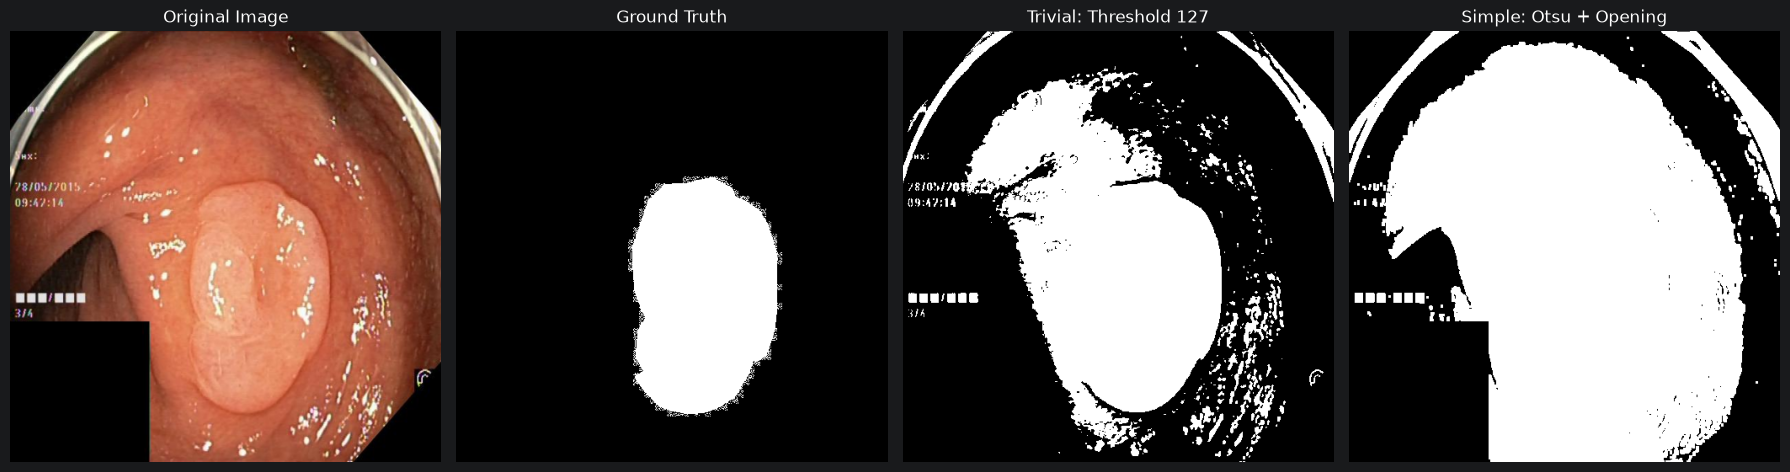

In [18]:
# ==========================================
# Cell 2: Segmentation Visualization
# ==========================================

import matplotlib.pyplot as plt

# Select one test sample
sample_index = 0

image_path, mask_path = test_pairs[sample_index]

# Load image and ground truth
image = load_image(image_path)
gt_mask = load_ground_truth(mask_path)

# Apply segmentation methods
trivial_pred = trivial_segmentation(image)
simple_pred = simple_segmentation(image)

# Display results
plt.figure(figsize=(18, 5))

plt.subplot(1, 4, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(gt_mask, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(trivial_pred, cmap="gray")
plt.title("Trivial: Threshold 127")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(simple_pred, cmap="gray")
plt.title("Simple: Otsu + Opening")
plt.axis("off")

plt.tight_layout()
plt.show()

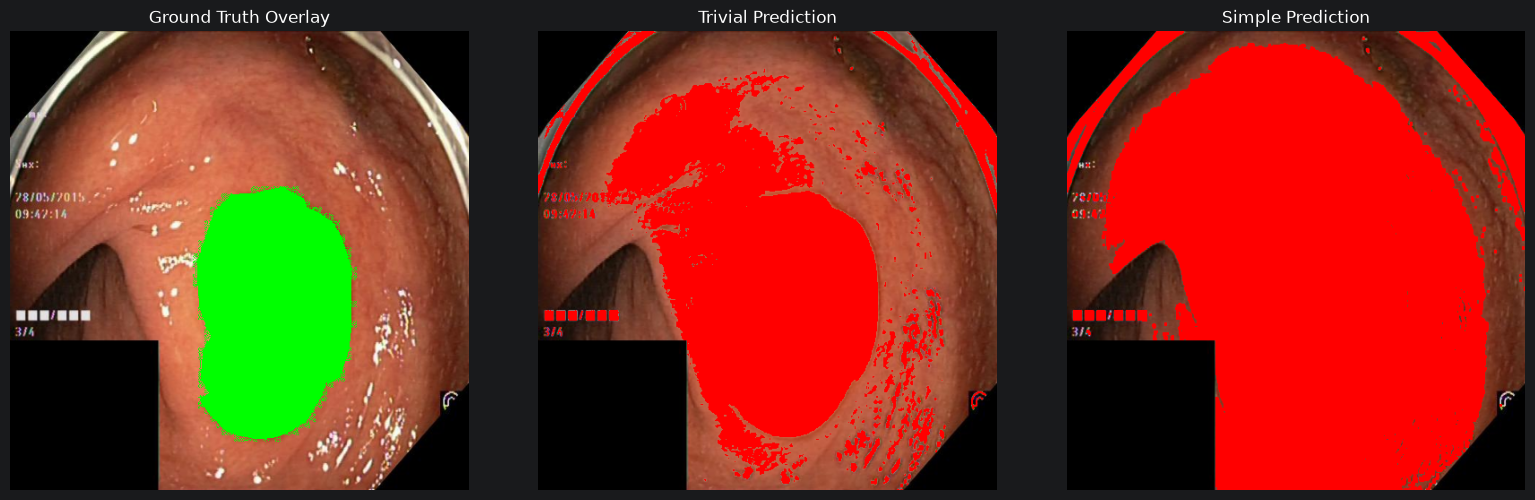

In [19]:
# ==========================================
# Cell 3: Segmentation Overlay
# ==========================================

# Create image copies
gt_overlay = image.copy()
trivial_overlay = image.copy()
simple_overlay = image.copy()

# Apply Ground Truth mask
gt_overlay[gt_mask > 0] = [0, 255, 0]

# Apply Trivial prediction
trivial_overlay[trivial_pred > 0] = [255, 0, 0]

# Apply Simple prediction
simple_overlay[simple_pred > 0] = [255, 0, 0]

# Display overlays
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(gt_overlay)
plt.title("Ground Truth Overlay")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(trivial_overlay)
plt.title("Trivial Prediction")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(simple_overlay)
plt.title("Simple Prediction")
plt.axis("off")

plt.tight_layout()
plt.show()

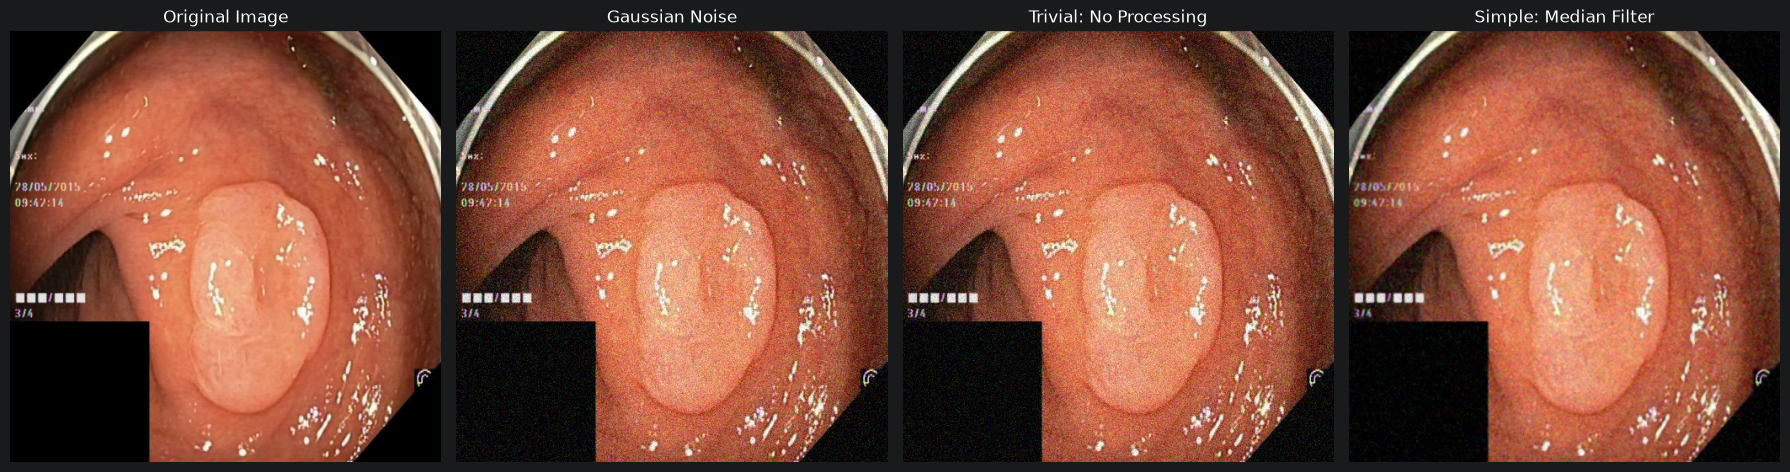

In [20]:
# ==========================================
# Cell 4: Restoration Visualization
# ==========================================

# Select test sample
sample_index = 0

image_path, mask_path = test_pairs[sample_index]

# Load clean image
clean_image = load_image(image_path)

# Add Gaussian noise
degraded_image = degrade_image(
    clean_image,
    method="gaussian",
    seed=42 + sample_index
)

# Apply restoration methods
trivial_result = trivial_restoration(degraded_image)

simple_result = simple_restoration(degraded_image)

# Display results
plt.figure(figsize=(18, 5))

plt.subplot(1, 4, 1)
plt.imshow(clean_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(degraded_image)
plt.title("Gaussian Noise")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(trivial_result)
plt.title("Trivial: No Processing")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(simple_result)
plt.title("Simple: Median Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

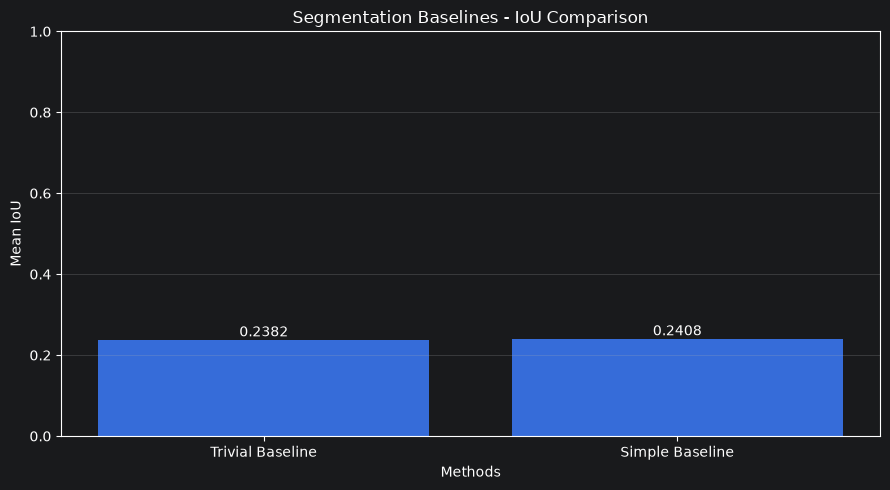

In [21]:
# ==========================================
# Cell 5: IoU Comparison
# ==========================================

methods = [
    "Trivial Baseline",
    "Simple Baseline"
]

iou_values = [
    results["trivial_iou"],
    results["simple_iou"]
]

plt.figure(figsize=(9, 5))

bars = plt.bar(methods, iou_values)

plt.title("Segmentation Baselines - IoU Comparison")
plt.xlabel("Methods")
plt.ylabel("Mean IoU")

plt.ylim(0, 1)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.4f}",
        ha="center",
        va="bottom"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

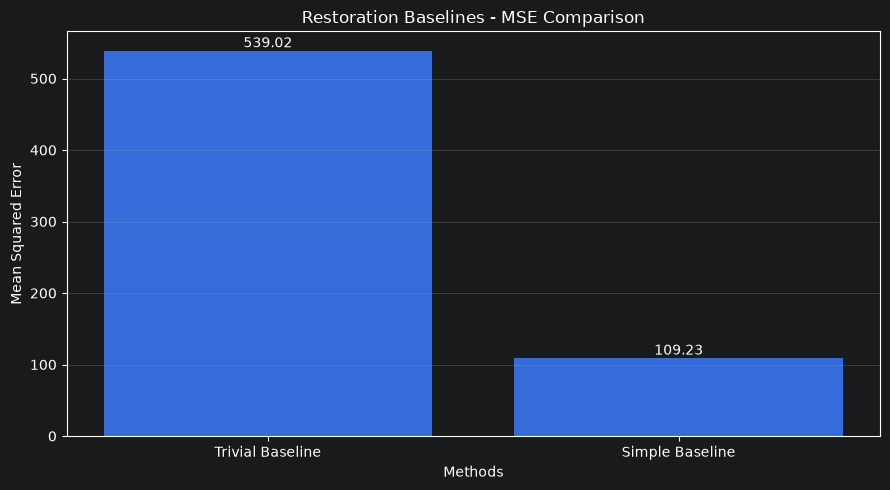

In [22]:
# ==========================================
# Cell 6: MSE Comparison
# ==========================================

methods = [
    "Trivial Baseline",
    "Simple Baseline"
]

mse_values = [
    results["trivial_mse"],
    results["simple_mse"]
]

plt.figure(figsize=(9, 5))

bars = plt.bar(methods, mse_values)

plt.title("Restoration Baselines - MSE Comparison")
plt.xlabel("Methods")
plt.ylabel("Mean Squared Error")

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

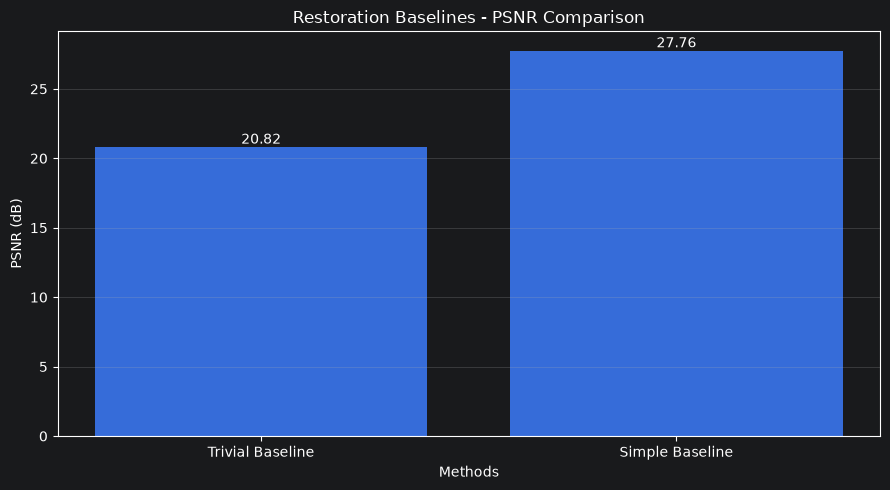

In [23]:
# ==========================================
# Cell 7: PSNR Comparison
# ==========================================

methods = [
    "Trivial Baseline",
    "Simple Baseline"
]

psnr_values = [
    results["trivial_psnr"],
    results["simple_psnr"]
]

plt.figure(figsize=(9, 5))

bars = plt.bar(methods, psnr_values)

plt.title("Restoration Baselines - PSNR Comparison")
plt.xlabel("Methods")
plt.ylabel("PSNR (dB)")

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
# ==========================================
# Cell 8: Final Baseline Results
# ==========================================

import pandas as pd

baseline_summary = pd.DataFrame({

    "Metric": [
        "IoU",
        "MSE",
        "PSNR (dB)"
    ],

    "Trivial Baseline": [
        results["trivial_iou"],
        results["trivial_mse"],
        results["trivial_psnr"]
    ],

    "Simple Baseline": [
        results["simple_iou"],
        results["simple_mse"],
        results["simple_psnr"]
    ]

})

print("BASELINE EVALUATION SUMMARY")

display(baseline_summary.round(4))

BASELINE EVALUATION SUMMARY


,Metric,Trivial Baseline,Simple Baseline
0,IoU,0.2382,0.2408
1,MSE,539.0198,109.2261
2,PSNR (dB),20.8182,27.7567
